# Paper figures and Table 1

Writes `paper/figures/fig*.pdf|png` and `paper/table1_master_rate_limits.{csv,tex}` when `SAVE_FIGURES = True`.
Each figure is drawn by a function in `knrates/figures.py`; the analysis notebooks named below show the same
figure with its results.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"
SAVE_FIGURES = True      # write paper/figures and Table 1
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A

ctx = NB.setup(SNAPSHOT, style="paper", labels="paper", save_figures=SAVE_FIGURES, fig_dir="paper/figures")
runs, lim, M = ctx.runs, ctx.lim, ctx.models

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


**Fig. 1**: sensitivity over the survey (notebook 02).

saved paper/figures/fig1_survey_volume_timeline.pdf
saved paper/figures/fig1_survey_volume_timeline.png


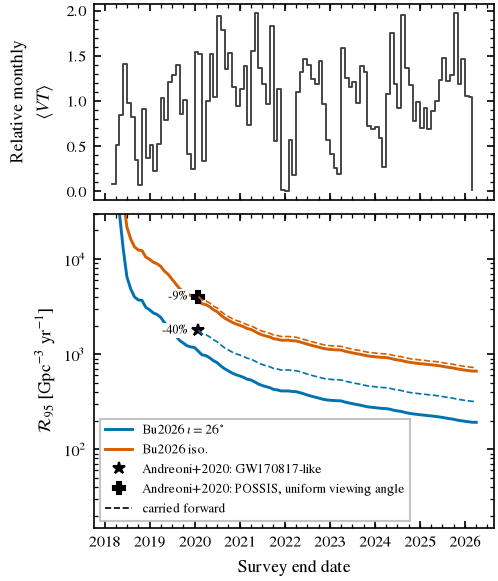

In [2]:
fig = F.sensitivity_timeline(ctx.tm, runs, M, ["andreoni2020_gw170817", "andreoni2020_possis_isotropic"])
ctx.save(fig, "fig1_survey_volume_timeline"); plt.show()

**Fig. 2**: viewing angle (notebook 03).

saved paper/figures/fig2_inclination_anatomy.pdf
saved paper/figures/fig2_inclination_anatomy.png


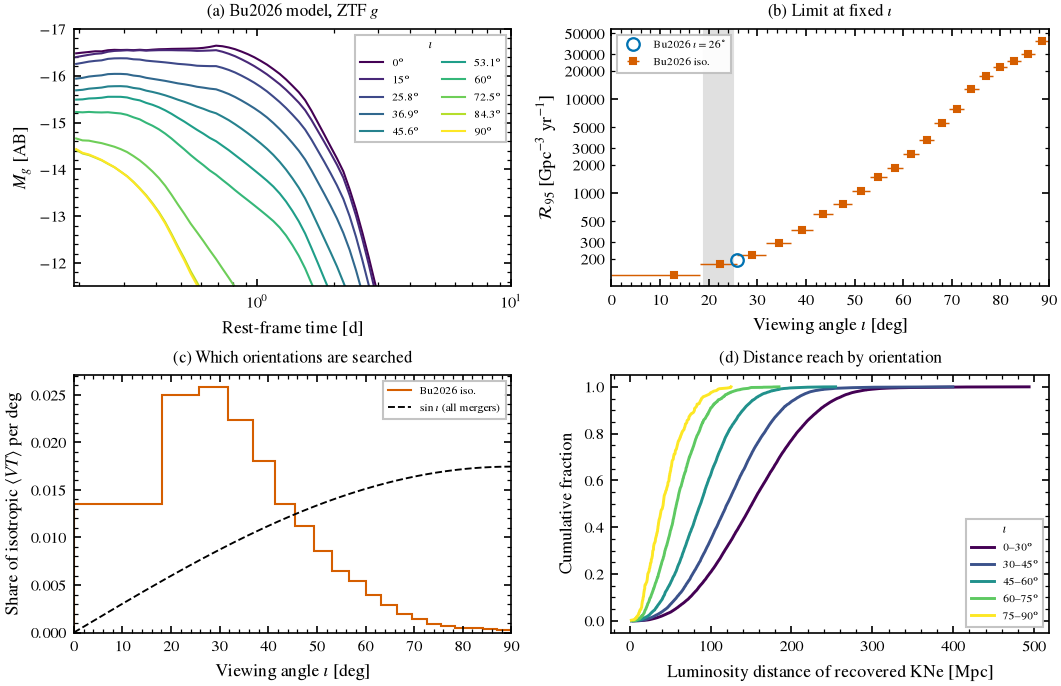

In [3]:
fig = F.viewing_angle(ctx.src, runs, lim, ctx.snap.get("models_lightcurves"), ["mooley2022_gw170817_viewing_angle"])
ctx.save(fig, "fig2_inclination_anatomy"); plt.show()

**Fig. 3**: limits vs. literature (notebook 01).

saved paper/figures/fig3_rate_limits_master.pdf
saved paper/figures/fig3_rate_limits_master.png


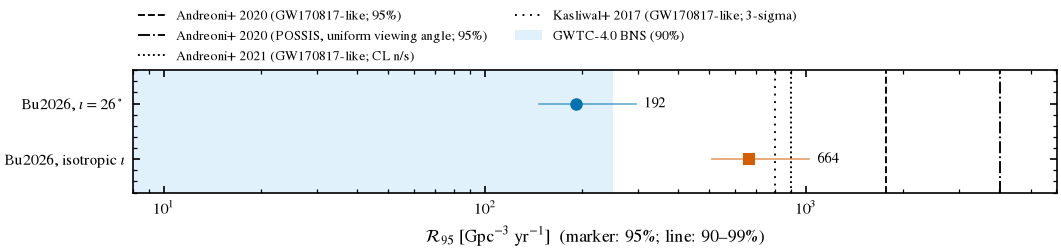

In [4]:
fig = F.rate_limits(lim, M, ["andreoni2020_gw170817", "andreoni2020_possis_isotropic", "andreoni2021_ztfrest_combined",
                             "kasliwal2017_iptf", "gwtc4_bns_rate"])
ctx.save(fig, "fig3_rate_limits_master"); plt.show()

**Fig. 4**: distance reach (notebook 01).

saved paper/figures/fig4_recovery_distance.pdf
saved paper/figures/fig4_recovery_distance.png


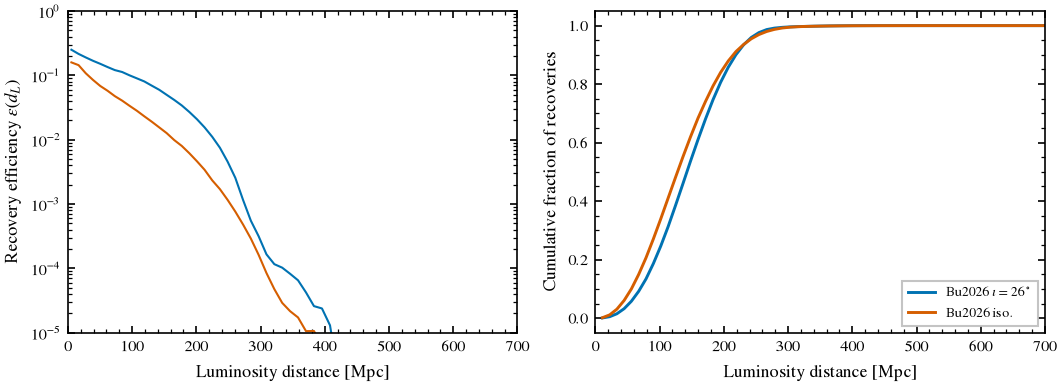

In [5]:
fig = F.distance_reach(ctx.zh, runs, M); ctx.save(fig, "fig4_recovery_distance"); plt.show()

**Fig. 5**: Monte Carlo convergence (notebook 04).

saved paper/figures/fig5_convergence_and_catastrophe.pdf
saved paper/figures/fig5_convergence_and_catastrophe.png


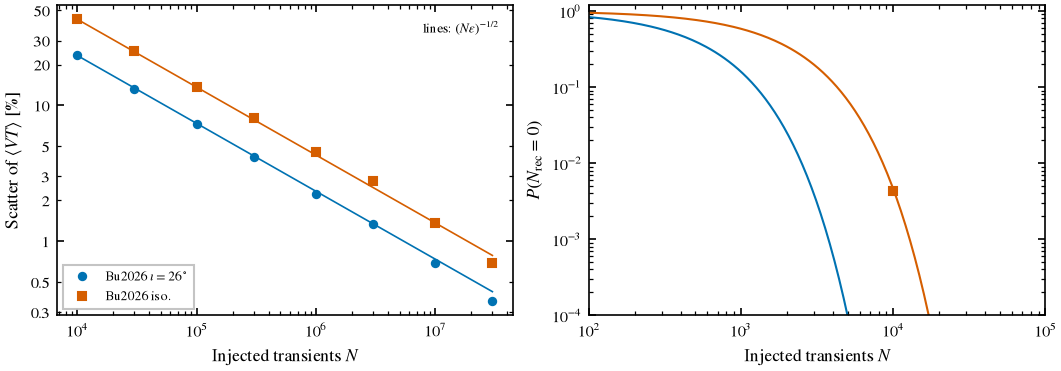

In [6]:
SIZES = [10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000]
conv = pd.concat([A.subsampling_convergence(runs, m, SIZES, 3000) for m in M], ignore_index=True)
fig = F.convergence(conv, lim, M); ctx.save(fig, "fig5_convergence_and_catastrophe"); plt.show()

**Fig. 6** (companion paper): criteria response (notebook 05).

saved paper/figures/fig6_criteria_sensitivity.pdf
saved paper/figures/fig6_criteria_sensitivity.png


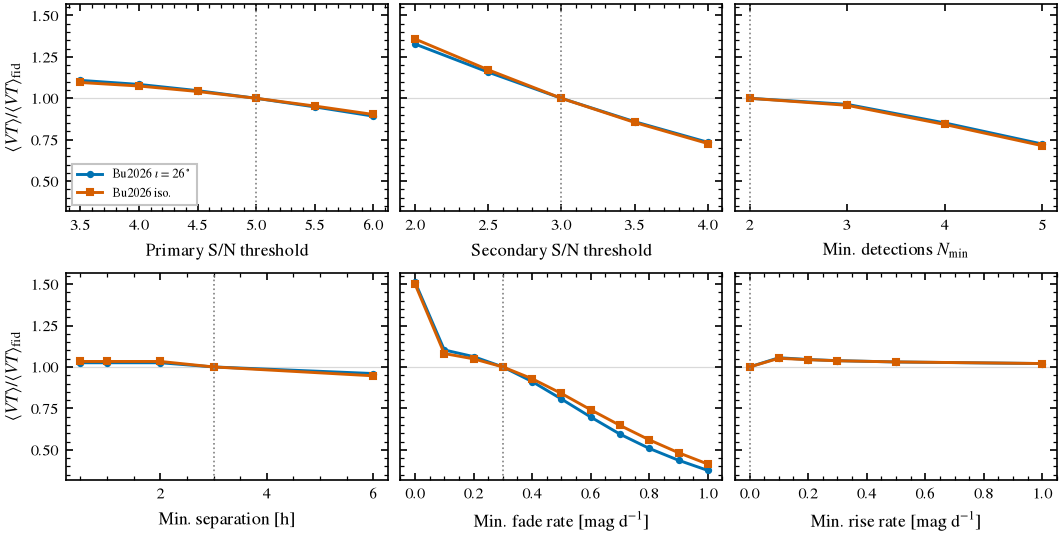

In [7]:
fig = F.criteria_one_at_a_time(ctx.snap["suite02_slices_1d"], ctx.snap["suite02_fiducial"])
ctx.save(fig, "fig6_criteria_sensitivity"); plt.show()

**Table 1**: rate limits.

In [8]:
tab, tex, colfmt = F.table1(lim, runs, M)
display(tex)
if SAVE_FIGURES:   # same switch as the figures, so a preview never overwrites the paper table
    tab.to_csv(ROOT / "paper/table1_master_rate_limits.csv", index=False)
    (ROOT / "paper/table1_master_rate_limits.tex").write_text(tex.to_latex(index=False, escape=False, float_format="%.0f", column_format=colfmt))
    print("wrote paper/table1_master_rate_limits.{csv,tex}")

,Model,Parameters,$N_{\rm rec}$,$\langle VT\rangle$ [$10^{-3}$ Gpc$^3$ yr],$\mathcal{R}_{90}$,$\mathcal{R}_{95}$,$\mathcal{R}_{99}$
0,"Bu2026, $\iota=26^\circ$","$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",184316,15.60 $\pm$ 0.04,147.6,192,295.2
1,"Bu2026, isotropic $\iota$","$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",53948,4.51 $\pm$ 0.02,510,663.6,1020


wrote paper/table1_master_rate_limits.{csv,tex}
